# Лабораторная работа № 1
## Линейная регрессия и снижение размерности методом PCA

**Дисциплина:** «Системы искусственного интеллекта и машинное обучение»  
**Вариант:** прогнозирование цены автомобиля по набору его характеристик  
**Данные:** локальный файл `imports-85.csv` (автомобили из набора Automobile / Imports-85).

### 1. Введение

Цель работы — построить и сравнить линейную регрессию, лассо и гребневую регрессию для непрерывной целевой переменной `price`. Рассмотрены распределения и корреляции признаков, рассчитан VIF, затем проверено, как стандартизация и метод главных компонент (PCA) влияют на мультиколлинеарность и качество прогноза. Все результаты получены на одном разбиении 80/20; подбор параметров и кросс-валидация выполняются только на обучающей части.


In [24]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
DATA_FILE = Path("imports-85.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError("Положите imports-85.csv рядом с lab1.ipynb")


### 2. Описание датасета и первичный анализ

Исходный набор Automobile опубликован в [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/10/automobile); он также размещен на [Kaggle](https://www.kaggle.com/datasets/fazilbtopal/auto85/versions/2). Локальный CSV содержит **199 строк и 26 столбцов**, то есть это подготовленная версия исходного набора из 205 наблюдений. Целевая переменная `price` — числовая цена автомобиля. Признаки описывают размеры, массу, двигатель, расход топлива, марку и конструкцию автомобиля. Символ `?` в файле означает пропуск; поэтому при загрузке он переводится в `NaN`.

Ниже показаны размеры данных, пример строк, типы переменных и описательная статистика. Графики помогают заметить асимметрию цены, различие масштабов числовых признаков и частоты категорий.


In [25]:
raw = pd.read_csv(DATA_FILE, na_values="?")
numeric_from_text = ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm"]
raw[numeric_from_text] = raw[numeric_from_text].apply(pd.to_numeric, errors="coerce")

print(f"Размер исходной таблицы: {raw.shape[0]} строк × {raw.shape[1]} столбцов")
print(f"Числовых признаков: {raw.select_dtypes(include=np.number).shape[1] - 1}; "
      f"категориальных: {raw.select_dtypes(exclude=np.number).shape[1]}")
print("Пропуски по столбцам:")
print(raw.isna().sum().loc[lambda s: s.gt(0)].to_string())
print("Первые три записи:")
display(raw.head(3))
print("Цена, доллары США:")
display(raw["price"].describe().round(1).to_frame("value"))


Размер исходной таблицы: 199 строк × 26 столбцов
Числовых признаков: 15; категориальных: 10
Пропуски по столбцам:
normalized-losses    36
bore                  4
stroke                4
horsepower            2
peak-rpm              2
Первые три записи:


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500


Цена, доллары США:


,value
count,199.0
mean,13242.6
std,7978.3
min,5118.0
25%,7775.0
50%,10295.0
75%,16501.5
max,45400.0


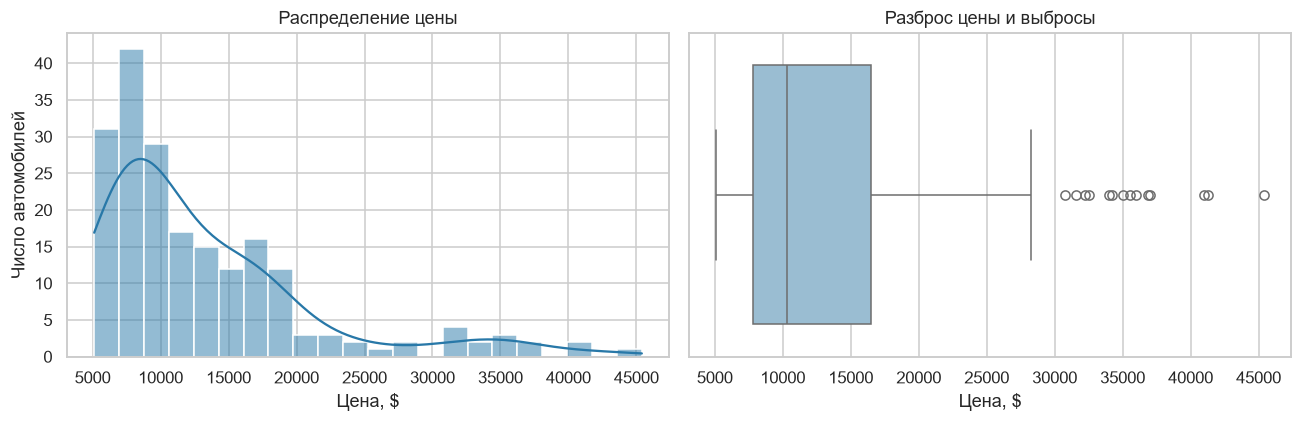

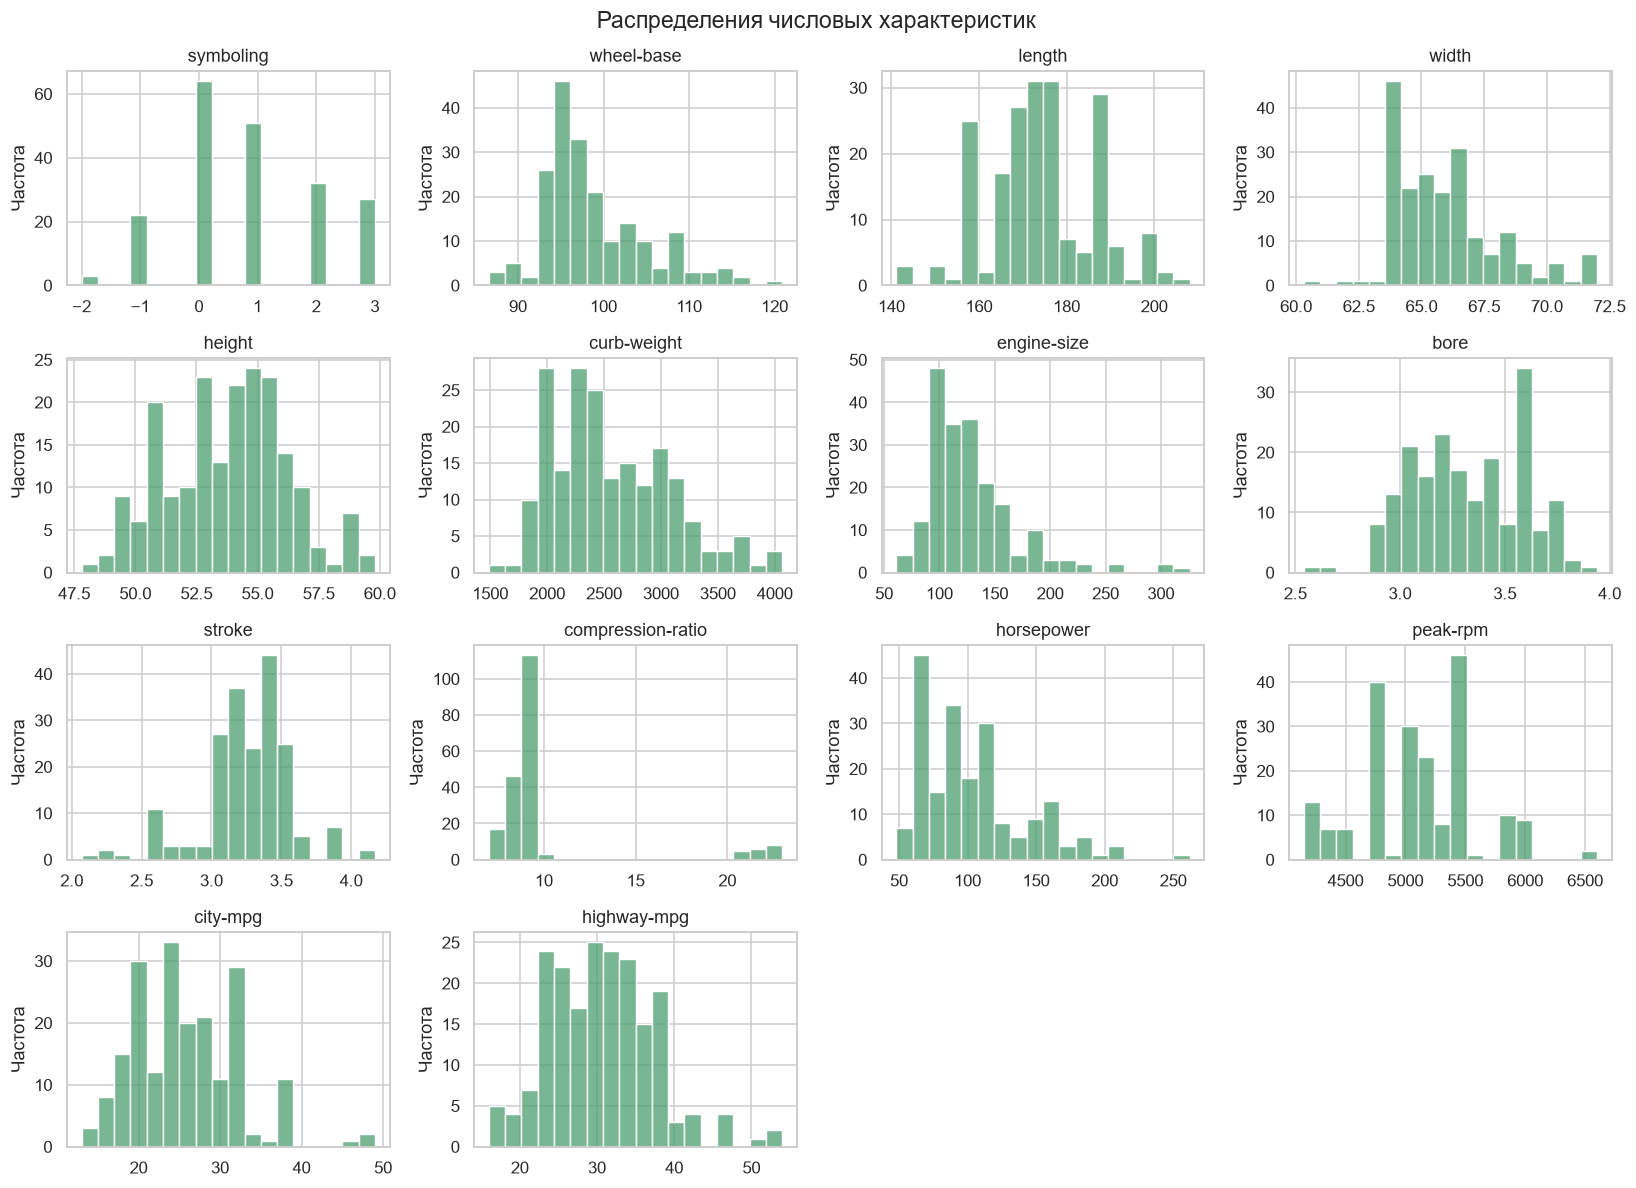

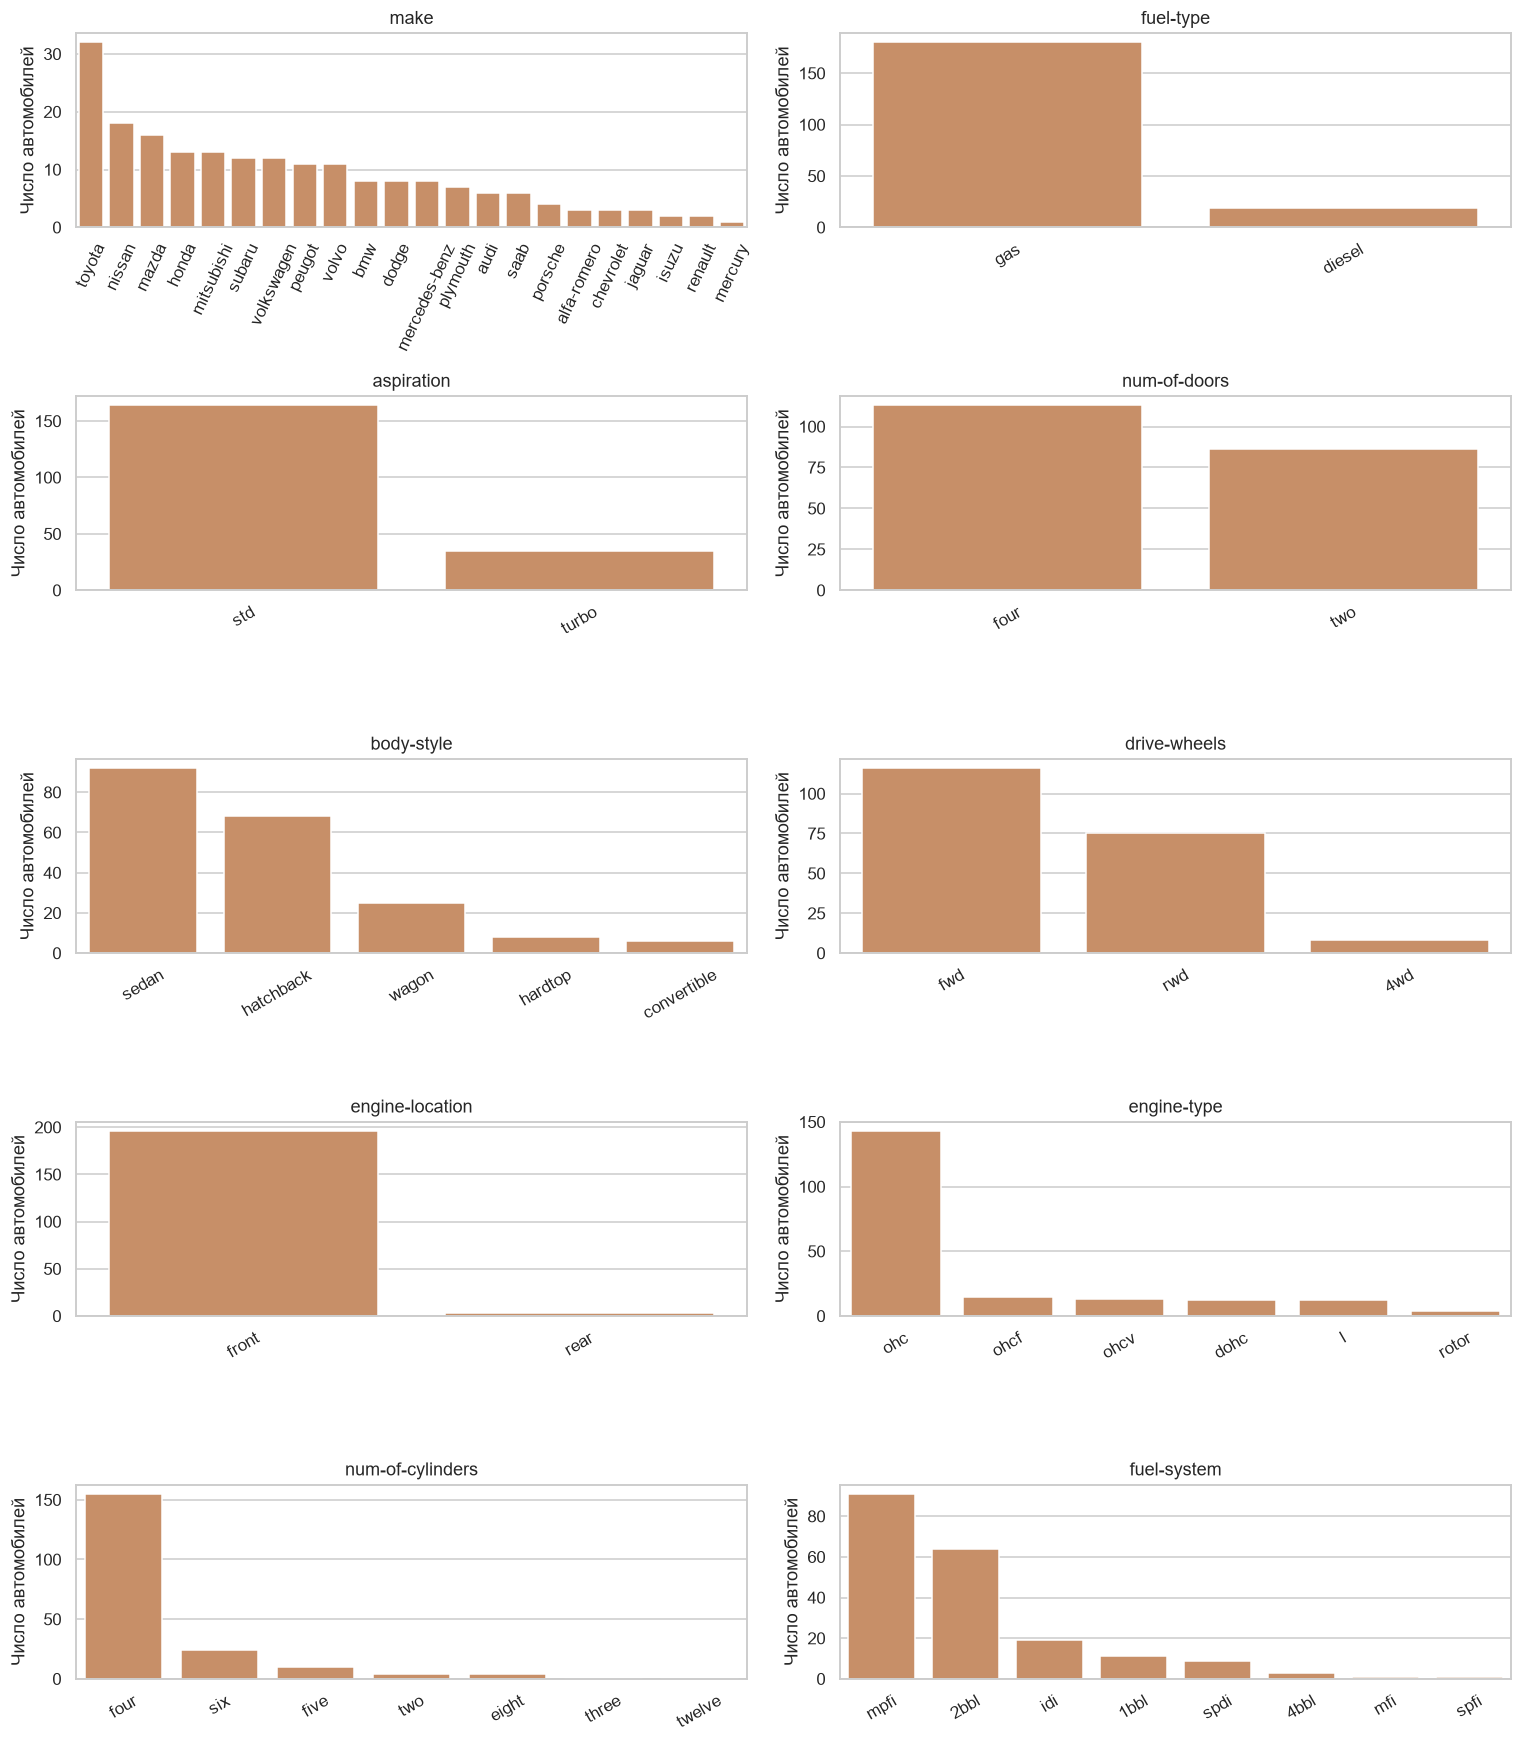

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(raw["price"].dropna(), bins=22, kde=True, ax=axes[0], color="#2878a8")
axes[0].set(title="Распределение цены", xlabel="Цена, $", ylabel="Число автомобилей")
sns.boxplot(x=raw["price"], ax=axes[1], color="#91bfdb")
axes[1].set(title="Разброс цены и выбросы", xlabel="Цена, $")
fig.tight_layout()
plt.show()

shown_numeric = ["symboling", "wheel-base", "length", "width", "height", "curb-weight", "engine-size",
                 "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
                 "city-mpg", "highway-mpg"]
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, column in zip(axes.flat, shown_numeric):
    sns.histplot(raw[column].dropna(), bins=18, ax=ax, color="#4c9f70")
    ax.set(title=column, xlabel="", ylabel="Частота")
for ax in axes.flat[len(shown_numeric):]:
    ax.axis("off")
fig.suptitle("Распределения числовых характеристик", fontsize=15)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(5, 2, figsize=(14, 16))
for ax, column in zip(axes.flat, raw.select_dtypes(exclude=np.number).columns):
    sns.countplot(data=raw, x=column, order=raw[column].value_counts().index, ax=ax,
                  color="#d78c58")
    ax.set(title=column, xlabel="", ylabel="Число автомобилей")
    ax.tick_params(axis="x", rotation=65 if raw[column].nunique() > 8 else 30)
fig.tight_layout()
plt.show()


**Наблюдение.** Цена и ряд технических характеристик распределены несимметрично. Единицы измерения признаков сильно отличаются: например, длина кузова, масса и обороты двигателя. Поэтому перед регуляризованной регрессией и PCA требуется стандартизация.

### 3. Подготовка данных

У `normalized-losses` много пропусков, и это страховой показатель, который для задачи прогноза цены не обязателен. Столбец удаляется целиком; строки с оставшимися пропусками удаляются. Категориальные признаки кодируются One-Hot Encoding с удалением одной базовой категории. Для неизвестной категории в тестовой выборке используется `handle_unknown="ignore"`. Такая категория кодируется нулями: модель не могла выучить для нее отдельный коэффициент. Это ожидаемая ситуация для редких категорий; предупреждение скрыто только во время предсказания. Далее все закодированные признаки стандартизируются. Эти преобразования обучаются внутри `Pipeline` только на соответствующем обучающем наборе — отдельно при каждом разбиении кросс-валидации.


In [27]:
clean = raw.drop(columns="normalized-losses").dropna().copy()
clean = clean.loc[clean["price"].gt(0)]
X = clean.drop(columns="price")
y = clean["price"]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"После очистки: {len(clean)} наблюдений; удалено {len(raw) - len(clean)} строк")
print(f"Обучающая выборка: {len(X_train)}; тестовая: {len(X_test)}")
print(f"Числовые признаки ({len(numeric_features)}): {', '.join(numeric_features)}")
print(f"Категориальные признаки ({len(categorical_features)}): {', '.join(categorical_features)}")
print(f"Пропусков после очистки: {int(clean.isna().sum().sum())}")


После очистки: 193 наблюдений; удалено 6 строк
Обучающая выборка: 154; тестовая: 39
Числовые признаки (14): symboling, wheel-base, length, width, height, curb-weight, engine-size, bore, stroke, compression-ratio, horsepower, peak-rpm, city-mpg, highway-mpg
Категориальные признаки (10): make, fuel-type, aspiration, num-of-doors, body-style, drive-wheels, engine-location, engine-type, num-of-cylinders, fuel-system
Пропусков после очистки: 0


### 4. Корреляции и мультиколлинеарность

Матрица Пирсона ниже включает только числовые столбцы: для категорий числовой порядок отсутствует. VIF вычисляется для числовых **предикторов**, без целевой цены. Формула: $VIF_j=1/(1-R_j^2)$, где $R_j^2$ получен при регрессии $j$-го признака на остальные. Значения выше 5 рассматриваются как указание на существенную взаимосвязь признаков. Диагностика считается по обучающей части, чтобы тестовая оставалась независимой.


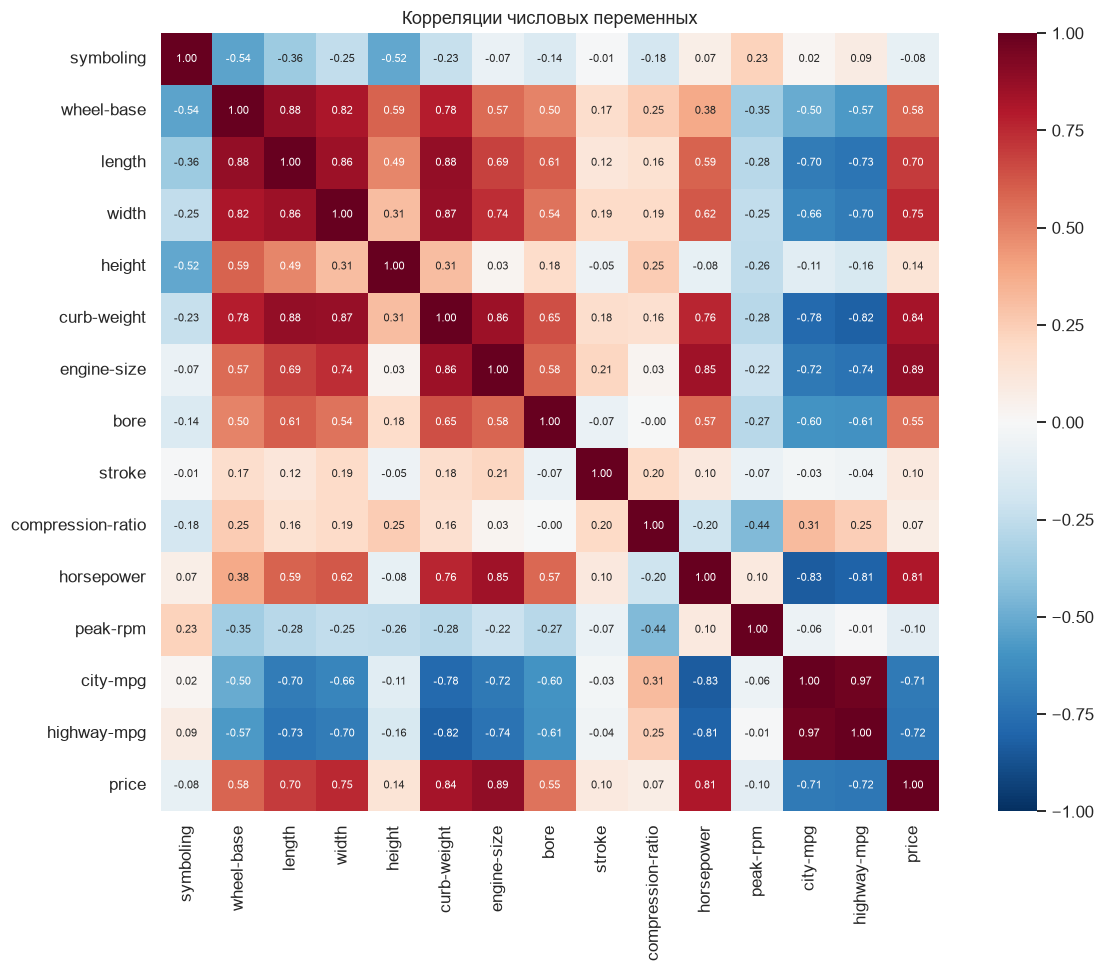

,Признак,VIF
12,city-mpg,27.60
13,highway-mpg,24.91
5,curb-weight,20.84
1,wheel-base,10.40
2,length,9.76
10,horsepower,8.45
6,engine-size,7.43
3,width,5.40
9,compression-ratio,2.62
4,height,2.41


Признаков с VIF > 5: 8 из 14


In [28]:
corr = clean[numeric_features + ["price"]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.title("Корреляции числовых переменных")
plt.tight_layout()
plt.show()

vif_input = pd.DataFrame(StandardScaler().fit_transform(X_train[numeric_features]),
                         columns=numeric_features)
vif_table = pd.DataFrame({
    "Признак": numeric_features,
    "VIF": [variance_inflation_factor(vif_input.to_numpy(), i)
            for i in range(vif_input.shape[1])],
}).sort_values("VIF", ascending=False)
display(vif_table.round(2))
print(f"Признаков с VIF > 5: {(vif_table['VIF'] > 5).sum()} из {len(vif_table)}")


VIF показывает взаимосвязь **числовых** характеристик; после One-Hot Encoding могут возникать и дополнительные зависимости между категориальными индикаторами. Наибольшие корреляции обычно ожидаются для размеров автомобиля, его массы, объема двигателя и показателей расхода топлива. Из-за мультиколлинеарности отдельные коэффициенты обычной линейной регрессии могут быть нестабильны, даже если качество предсказания приемлемо.

### 5. Регрессии на исходных признаках

Используются три модели: обычная линейная регрессия (OLS), Lasso с $L_1$-штрафом и Ridge с $L_2$-штрафом. Для Lasso и Ridge коэффициент `alpha` выбирается по минимальному RMSE. Оценка по кросс-валидации вложенная: пять внешних складок для метрик и три внутренние складки для подбора `alpha`. После оценки параметры подбираются на всей обучающей части, модель обучается и проверяется на отложенном тесте.

RMSE и MAPE меньше — лучше; $R^2$ больше — лучше. MAPE здесь определена, так как все цены положительны. При интерпретации тестовых метрик важно учитывать малый размер выборки.


In [29]:
def make_pipeline(model, use_pca=False):
    encoding = ColumnTransformer([
        ("numbers", "passthrough", numeric_features),
        ("categories", OneHotEncoder(drop="first", handle_unknown="ignore",
                                     sparse_output=False), categorical_features),
    ])
    steps = [("encode", encoding), ("scale", StandardScaler())]
    if use_pca:
        steps.append(("pca", PCA(n_components=0.95, svd_solver="full")))
    steps.append(("regressor", model))
    return Pipeline(steps)


folds = KFold(n_splits=5, shuffle=True, random_state=42)
inner_folds = KFold(n_splits=3, shuffle=True, random_state=17)
alphas = np.logspace(-2, 3, 9)
scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2",
           "mape": "neg_mean_absolute_percentage_error"}


def assess_family(use_pca):
    rows, fitted = [], {}
    candidates = {
        "Linear": (LinearRegression(), None),
        "Lasso": (Lasso(max_iter=30000), {"regressor__alpha": alphas}),
        "Ridge": (Ridge(), {"regressor__alpha": alphas}),
    }
    for name, (model, grid) in candidates.items():
        pipe = make_pipeline(model, use_pca=use_pca)
        if grid is not None:
            selector = GridSearchCV(pipe, grid, scoring="neg_root_mean_squared_error",
                                    cv=inner_folds, n_jobs=1)
        else:
            selector = pipe
            alpha = np.nan
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Found unknown categories")
            warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
            cv = cross_validate(selector, X_train, y_train, scoring=scoring, cv=folds,
                                n_jobs=1, error_score="raise")
            selector.fit(X_train, y_train)
        if grid is not None:
            alpha = selector.best_params_["regressor__alpha"]
            pipe = selector.best_estimator_
        # Unknown categories are handled by the encoder; suppress only that expected warning.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Found unknown categories", category=UserWarning)
            pred = pipe.predict(X_test)
        fitted[name] = pipe
        rows.append({
            "Признаки": "PCA" if use_pca else "Исходные",
            "Модель": name,
            "alpha": alpha,
            "CV RMSE, $": -cv["test_rmse"].mean(),
            "CV R²": cv["test_r2"].mean(),
            "CV MAPE, %": -cv["test_mape"].mean() * 100,
            "Тест RMSE, $": np.sqrt(mean_squared_error(y_test, pred)),
            "Тест R²": r2_score(y_test, pred),
            "Тест MAPE, %": mean_absolute_percentage_error(y_test, pred) * 100,
        })
    return pd.DataFrame(rows), fitted


base_metrics, base_models = assess_family(use_pca=False)
display(base_metrics.round(2))


,Признаки,Модель,alpha,"CV RMSE, $",CV R²,"CV MAPE, %","Тест RMSE, $",Тест R²,"Тест MAPE, %"
0,Исходные,Linear,NaN,2365.49,0.89,14.31,3378.20,0.90,14.89
1,Исходные,Lasso,56.23,2308.39,0.90,12.93,3263.42,0.91,12.23
2,Исходные,Ridge,13.34,1992.97,0.92,12.66,3452.92,0.89,12.93


### 6. Стандартизация и метод главных компонент

PCA строит ортогональные компоненты из стандартизированных признаков. Доля сохраненной дисперсии установлена на уровне **не менее 95%**. На графике каменистой осыпи показаны индивидуальные и накопленные доли дисперсии. График строится только по обучающей выборке. В моделях ниже PCA заново подстраивается на каждой обучающей складке, поэтому информация из валидационной и тестовой частей в компоненты не попадает.


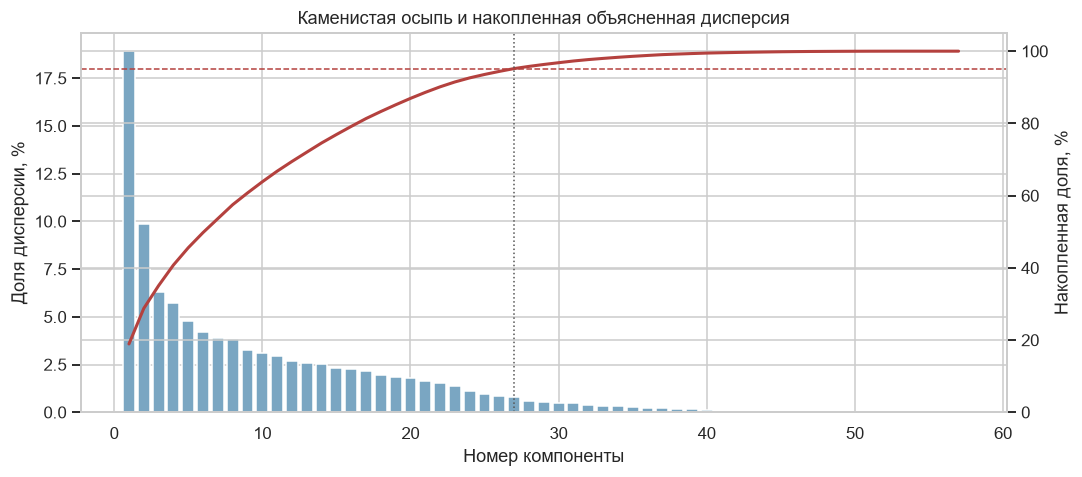

После кодирования: 57 признаков
Для 95% дисперсии достаточно 27 компонент (95.2% дисперсии)
Максимальная абсолютная корреляция разных компонент: 1.09e-15


In [30]:
diagnostic = make_pipeline(LinearRegression(), use_pca=False)
train_encoded = diagnostic.named_steps["encode"].fit_transform(X_train)
train_scaled = diagnostic.named_steps["scale"].fit_transform(train_encoded)
pca_full = PCA(svd_solver="full").fit(train_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
component_count = int(np.searchsorted(cumulative, 0.95) + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
x_axis = np.arange(1, len(cumulative) + 1)
ax.bar(x_axis, pca_full.explained_variance_ratio_ * 100, color="#7aa6c2",
       label="Отдельная компонента")
ax.set(xlabel="Номер компоненты", ylabel="Доля дисперсии, %",
       title="Каменистая осыпь и накопленная объясненная дисперсия")
ax2 = ax.twinx()
ax2.plot(x_axis, cumulative * 100, color="#b4413e", linewidth=2,
         label="Накопленная доля")
ax2.axhline(95, color="#b4413e", linestyle="--", linewidth=1)
ax2.axvline(component_count, color="#555555", linestyle=":", linewidth=1)
ax2.set(ylabel="Накопленная доля, %", ylim=(0, 105))
fig.tight_layout()
plt.show()

print(f"После кодирования: {train_scaled.shape[1]} признаков")
print(f"Для 95% дисперсии достаточно {component_count} компонент "
      f"({cumulative[component_count - 1]:.1%} дисперсии)")
scores = PCA(n_components=component_count, svd_solver="full").fit_transform(train_scaled)
pc_corr = np.corrcoef(scores, rowvar=False)
off_diagonal = np.abs(pc_corr - np.eye(component_count))
print(f"Максимальная абсолютная корреляция разных компонент: "
      f"{off_diagonal.max():.2e}")


Компоненты ортогональны на обучающих данных: их попарные корреляции практически равны нулю. Это устраняет линейную мультиколлинеарность **между компонентами** и сокращает размерность, но не гарантирует улучшения прогноза: часть отброшенной дисперсии может быть связана с ценой.

### 7. Повторное обучение и сравнение

Используются те же разбиение, внешние и внутренние складки и сетка `alpha`. Единственное изменение — вставка PCA после стандартизации и до регрессии.


,Признаки,Модель,alpha,"CV RMSE, $",CV R²,"CV MAPE, %","Тест RMSE, $",Тест R²,"Тест MAPE, %"
0,Исходные,Linear,NaN,2365.49,0.89,14.31,3378.20,0.90,14.89
1,Исходные,Lasso,56.23,2308.39,0.90,12.93,3263.42,0.91,12.23
2,Исходные,Ridge,13.34,1992.97,0.92,12.66,3452.92,0.89,12.93
3,PCA,Linear,NaN,2613.17,0.87,16.11,3723.71,0.88,17.42
4,PCA,Lasso,237.14,2719.89,0.86,15.87,4222.86,0.84,16.28
5,PCA,Ridge,56.23,2602.86,0.87,15.34,4009.83,0.86,16.04


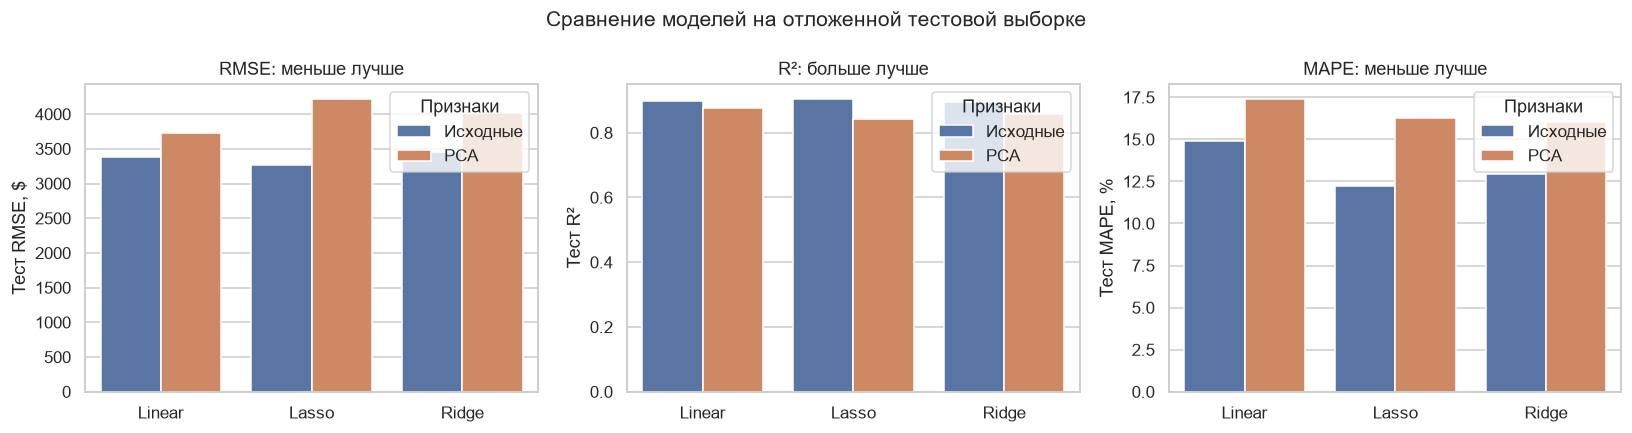

Лучшая по средней CV RMSE: Ridge / Исходные; CV RMSE = 1993 $, тест RMSE = 3453 $, тест R² = 0.894, тест MAPE = 12.9%


In [31]:
pca_metrics, pca_models = assess_family(use_pca=True)
comparison = pd.concat([base_metrics, pca_metrics], ignore_index=True)
display(comparison.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes,
    ["Тест RMSE, $", "Тест R²", "Тест MAPE, %"],
    ["RMSE: меньше лучше", "R²: больше лучше", "MAPE: меньше лучше"],
):
    sns.barplot(data=comparison, x="Модель", y=metric, hue="Признаки", ax=ax)
    ax.set(title=title, xlabel="", ylabel=metric)
fig.suptitle("Сравнение моделей на отложенной тестовой выборке", fontsize=14)
fig.tight_layout()
plt.show()

best_cv = comparison.loc[comparison["CV RMSE, $"].idxmin()]
print(f"Лучшая по средней CV RMSE: {best_cv['Модель']} / {best_cv['Признаки']}; "
      f"CV RMSE = {best_cv['CV RMSE, $']:.0f} $, "
      f"тест RMSE = {best_cv['Тест RMSE, $']:.0f} $, "
      f"тест R² = {best_cv['Тест R²']:.3f}, "
      f"тест MAPE = {best_cv['Тест MAPE, %']:.1f}%")


### 8. Заключение

В обучающей части VIF выше 5 обнаружен у 8 из 14 числовых признаков. PCA сократил 57 закодированных признаков до 27 при сохранении 95,2% дисперсии и сделал компоненты некоррелированными. На данном разбиении PCA увеличил тестовый RMSE для всех трех моделей: линейной — примерно на 346 $, Lasso — на 959 $, Ridge — на 557 $. Значит, устранение мультиколлинеарности через PCA здесь не повысило точность прогноза.

Минимальная средняя RMSE на внешних складках — у **Ridge на исходных признаках**: 1993 $. На тесте для нее RMSE = 3453 $, $R^2$ = 0,894, MAPE = 12,9%. У Lasso тестовый RMSE ниже (3263 $), но по заранее выбранному правилу CV предпочтение отдается Ridge. Разовый тест на небольшой выборке чувствителен к составу автомобилей. Тестовая выборка не участвует в выборе `alpha` или числа компонент.


In [32]:
for name in ["Linear", "Lasso", "Ridge"]:
    before = base_metrics.set_index("Модель").loc[name]
    after = pca_metrics.set_index("Модель").loc[name]
    delta = after["Тест RMSE, $"] - before["Тест RMSE, $"]
    print(f"{name}: изменение тестового RMSE после PCA = {delta:+.0f} $; "
          f"R²: {before['Тест R²']:.3f} → {after['Тест R²']:.3f}; "
          f"MAPE: {before['Тест MAPE, %']:.1f}% → {after['Тест MAPE, %']:.1f}%")
print(f"Итог: {len(clean)} записей, {len(X_train)}/{len(X_test)} train/test, "
      f"{component_count} компонент из {train_scaled.shape[1]} закодированных признаков.")


Linear: изменение тестового RMSE после PCA = +346 $; R²: 0.898 → 0.877; MAPE: 14.9% → 17.4%
Lasso: изменение тестового RMSE после PCA = +959 $; R²: 0.905 → 0.841; MAPE: 12.2% → 16.3%
Ridge: изменение тестового RMSE после PCA = +557 $; R²: 0.894 → 0.857; MAPE: 12.9% → 16.0%
Итог: 193 записей, 154/39 train/test, 27 компонент из 57 закодированных признаков.


### 9. Список источников

1. Schlimmer, J. **Automobile** [набор данных]. UCI Machine Learning Repository, 1985. DOI: [10.24432/C5B01C](https://doi.org/10.24432/C5B01C).
2. [Публикация набора Automobile на Kaggle](https://www.kaggle.com/datasets/fazilbtopal/auto85/versions/2).
3. scikit-learn: [перекрестная проверка](https://scikit-learn.org/stable/modules/cross_validation.html), [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [линейные модели](https://scikit-learn.org/stable/modules/linear_model.html).
4. statsmodels: [Variance Inflation Factor](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).

### 10. Приложение. Полный листинг программного кода

Ниже приведен полный исполняемый листинг всех кодовых ячеек этого ноутбука в порядке выполнения. Для повторения результата выполните **Run All** из папки с `imports-85.csv`.

```python
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
DATA_FILE = Path("imports-85.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError("Положите imports-85.csv рядом с lab1.ipynb")


raw = pd.read_csv(DATA_FILE, na_values="?")
numeric_from_text = ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm"]
raw[numeric_from_text] = raw[numeric_from_text].apply(pd.to_numeric, errors="coerce")

print(f"Размер исходной таблицы: {raw.shape[0]} строк × {raw.shape[1]} столбцов")
print(f"Числовых признаков: {raw.select_dtypes(include=np.number).shape[1] - 1}; "
      f"категориальных: {raw.select_dtypes(exclude=np.number).shape[1]}")
print("Пропуски по столбцам:")
print(raw.isna().sum().loc[lambda s: s.gt(0)].to_string())
print("Первые три записи:")
display(raw.head(3))
print("Цена, доллары США:")
display(raw["price"].describe().round(1).to_frame("value"))


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(raw["price"].dropna(), bins=22, kde=True, ax=axes[0], color="#2878a8")
axes[0].set(title="Распределение цены", xlabel="Цена, $", ylabel="Число автомобилей")
sns.boxplot(x=raw["price"], ax=axes[1], color="#91bfdb")
axes[1].set(title="Разброс цены и выбросы", xlabel="Цена, $")
fig.tight_layout()
plt.show()

shown_numeric = ["symboling", "wheel-base", "length", "width", "height", "curb-weight", "engine-size",
                 "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm",
                 "city-mpg", "highway-mpg"]
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, column in zip(axes.flat, shown_numeric):
    sns.histplot(raw[column].dropna(), bins=18, ax=ax, color="#4c9f70")
    ax.set(title=column, xlabel="", ylabel="Частота")
for ax in axes.flat[len(shown_numeric):]:
    ax.axis("off")
fig.suptitle("Распределения числовых характеристик", fontsize=15)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(5, 2, figsize=(14, 16))
for ax, column in zip(axes.flat, raw.select_dtypes(exclude=np.number).columns):
    sns.countplot(data=raw, x=column, order=raw[column].value_counts().index, ax=ax,
                  color="#d78c58")
    ax.set(title=column, xlabel="", ylabel="Число автомобилей")
    ax.tick_params(axis="x", rotation=65 if raw[column].nunique() > 8 else 30)
fig.tight_layout()
plt.show()


clean = raw.drop(columns="normalized-losses").dropna().copy()
clean = clean.loc[clean["price"].gt(0)]
X = clean.drop(columns="price")
y = clean["price"]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"После очистки: {len(clean)} наблюдений; удалено {len(raw) - len(clean)} строк")
print(f"Обучающая выборка: {len(X_train)}; тестовая: {len(X_test)}")
print(f"Числовые признаки ({len(numeric_features)}): {', '.join(numeric_features)}")
print(f"Категориальные признаки ({len(categorical_features)}): {', '.join(categorical_features)}")
print(f"Пропусков после очистки: {int(clean.isna().sum().sum())}")


corr = clean[numeric_features + ["price"]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.title("Корреляции числовых переменных")
plt.tight_layout()
plt.show()

vif_input = pd.DataFrame(StandardScaler().fit_transform(X_train[numeric_features]),
                         columns=numeric_features)
vif_table = pd.DataFrame({
    "Признак": numeric_features,
    "VIF": [variance_inflation_factor(vif_input.to_numpy(), i)
            for i in range(vif_input.shape[1])],
}).sort_values("VIF", ascending=False)
display(vif_table.round(2))
print(f"Признаков с VIF > 5: {(vif_table['VIF'] > 5).sum()} из {len(vif_table)}")


def make_pipeline(model, use_pca=False):
    encoding = ColumnTransformer([
        ("numbers", "passthrough", numeric_features),
        ("categories", OneHotEncoder(drop="first", handle_unknown="ignore",
                                     sparse_output=False), categorical_features),
    ])
    steps = [("encode", encoding), ("scale", StandardScaler())]
    if use_pca:
        steps.append(("pca", PCA(n_components=0.95, svd_solver="full")))
    steps.append(("regressor", model))
    return Pipeline(steps)


folds = KFold(n_splits=5, shuffle=True, random_state=42)
inner_folds = KFold(n_splits=3, shuffle=True, random_state=17)
alphas = np.logspace(-2, 3, 9)
scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2",
           "mape": "neg_mean_absolute_percentage_error"}


def assess_family(use_pca):
    rows, fitted = [], {}
    candidates = {
        "Linear": (LinearRegression(), None),
        "Lasso": (Lasso(max_iter=30000), {"regressor__alpha": alphas}),
        "Ridge": (Ridge(), {"regressor__alpha": alphas}),
    }
    for name, (model, grid) in candidates.items():
        pipe = make_pipeline(model, use_pca=use_pca)
        if grid is not None:
            selector = GridSearchCV(pipe, grid, scoring="neg_root_mean_squared_error",
                                    cv=inner_folds, n_jobs=1)
        else:
            selector = pipe
            alpha = np.nan
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Found unknown categories")
            warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
            cv = cross_validate(selector, X_train, y_train, scoring=scoring, cv=folds,
                                n_jobs=1, error_score="raise")
            selector.fit(X_train, y_train)
        if grid is not None:
            alpha = selector.best_params_["regressor__alpha"]
            pipe = selector.best_estimator_
        # Unknown categories are handled by the encoder; suppress only that expected warning.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Found unknown categories", category=UserWarning)
            pred = pipe.predict(X_test)
        fitted[name] = pipe
        rows.append({
            "Признаки": "PCA" if use_pca else "Исходные",
            "Модель": name,
            "alpha": alpha,
            "CV RMSE, $": -cv["test_rmse"].mean(),
            "CV R²": cv["test_r2"].mean(),
            "CV MAPE, %": -cv["test_mape"].mean() * 100,
            "Тест RMSE, $": np.sqrt(mean_squared_error(y_test, pred)),
            "Тест R²": r2_score(y_test, pred),
            "Тест MAPE, %": mean_absolute_percentage_error(y_test, pred) * 100,
        })
    return pd.DataFrame(rows), fitted


base_metrics, base_models = assess_family(use_pca=False)
display(base_metrics.round(2))


diagnostic = make_pipeline(LinearRegression(), use_pca=False)
train_encoded = diagnostic.named_steps["encode"].fit_transform(X_train)
train_scaled = diagnostic.named_steps["scale"].fit_transform(train_encoded)
pca_full = PCA(svd_solver="full").fit(train_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
component_count = int(np.searchsorted(cumulative, 0.95) + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
x_axis = np.arange(1, len(cumulative) + 1)
ax.bar(x_axis, pca_full.explained_variance_ratio_ * 100, color="#7aa6c2",
       label="Отдельная компонента")
ax.set(xlabel="Номер компоненты", ylabel="Доля дисперсии, %",
       title="Каменистая осыпь и накопленная объясненная дисперсия")
ax2 = ax.twinx()
ax2.plot(x_axis, cumulative * 100, color="#b4413e", linewidth=2,
         label="Накопленная доля")
ax2.axhline(95, color="#b4413e", linestyle="--", linewidth=1)
ax2.axvline(component_count, color="#555555", linestyle=":", linewidth=1)
ax2.set(ylabel="Накопленная доля, %", ylim=(0, 105))
fig.tight_layout()
plt.show()

print(f"После кодирования: {train_scaled.shape[1]} признаков")
print(f"Для 95% дисперсии достаточно {component_count} компонент "
      f"({cumulative[component_count - 1]:.1%} дисперсии)")
scores = PCA(n_components=component_count, svd_solver="full").fit_transform(train_scaled)
pc_corr = np.corrcoef(scores, rowvar=False)
off_diagonal = np.abs(pc_corr - np.eye(component_count))
print(f"Максимальная абсолютная корреляция разных компонент: "
      f"{off_diagonal.max():.2e}")


pca_metrics, pca_models = assess_family(use_pca=True)
comparison = pd.concat([base_metrics, pca_metrics], ignore_index=True)
display(comparison.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes,
    ["Тест RMSE, $", "Тест R²", "Тест MAPE, %"],
    ["RMSE: меньше лучше", "R²: больше лучше", "MAPE: меньше лучше"],
):
    sns.barplot(data=comparison, x="Модель", y=metric, hue="Признаки", ax=ax)
    ax.set(title=title, xlabel="", ylabel=metric)
fig.suptitle("Сравнение моделей на отложенной тестовой выборке", fontsize=14)
fig.tight_layout()
plt.show()

best_cv = comparison.loc[comparison["CV RMSE, $"].idxmin()]
print(f"Лучшая по средней CV RMSE: {best_cv['Модель']} / {best_cv['Признаки']}; "
      f"CV RMSE = {best_cv['CV RMSE, $']:.0f} $, "
      f"тест RMSE = {best_cv['Тест RMSE, $']:.0f} $, "
      f"тест R² = {best_cv['Тест R²']:.3f}, "
      f"тест MAPE = {best_cv['Тест MAPE, %']:.1f}%")


for name in ["Linear", "Lasso", "Ridge"]:
    before = base_metrics.set_index("Модель").loc[name]
    after = pca_metrics.set_index("Модель").loc[name]
    delta = after["Тест RMSE, $"] - before["Тест RMSE, $"]
    print(f"{name}: изменение тестового RMSE после PCA = {delta:+.0f} $; "
          f"R²: {before['Тест R²']:.3f} → {after['Тест R²']:.3f}; "
          f"MAPE: {before['Тест MAPE, %']:.1f}% → {after['Тест MAPE, %']:.1f}%")
print(f"Итог: {len(clean)} записей, {len(X_train)}/{len(X_test)} train/test, "
      f"{component_count} компонент из {train_scaled.shape[1]} закодированных признаков.")

```
